# Explaining Anomalies with Isolation Forest and SHAP #
This notebook is based on the youtube playlist/tutorial at: https://youtu.be/ucgR0E_LXCk?si=8fpyHEiHTOry9nzt  <br>
<br>
We dive deep into the world of anomaly detection with a focus on the Isolation Forest algorithm. Isolation Forest is a powerful machine learning model for identifying outliers in high-dimensional data, but understanding why an anomaly is detected can be a challenge. That's where SHAP (SHapley Additive exPlanations) comes in.

We'll explore how to use both KernelSHAP and TreeSHAP to interpret the contributions of individual features to anomaly scores. You'll learn how to visualize and break down these contributions, making it easier to understand and explain the decisions made by Isolation Forest. This is particularly valuable in real-world applications like fraud detection, where knowing the 'why' behind an anomaly is just as important as identifying it.

In [7]:
# Imports
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

import shap

from sklearn.ensemble import IsolationForest
from ucimlrepo import fetch_ucirepo

plt.rcParams.update({'figure.facecolor':'white'})

## Data Cleaning and Feature Engineering

In [8]:
# Fetch Dataset from UCI Repository
power_consumption = fetch_ucirepo(id=235)

print(power_consumption.variables)


c:\Users\JoeDavis\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


                    name     role         type  ... description units missing_values
0                   Date  Feature         Date  ...        None  None             no
1                   Time  Feature  Categorical  ...        None  None             no
2    Global_active_power  Feature   Continuous  ...        None  None             no
3  Global_reactive_power  Feature   Continuous  ...        None  None             no
4                Voltage  Feature   Continuous  ...        None  None             no
5       Global_intensity  Feature   Continuous  ...        None  None             no
6         Sub_metering_1  Feature   Continuous  ...        None  None             no
7         Sub_metering_2  Feature   Continuous  ...        None  None             no
8         Sub_metering_3  Feature   Continuous  ...        None  None             no

[9 rows x 7 columns]


In [ ]:
data = power_consumption.data.features
data['Date'] = pd.to_datetime(data['Date'], format='%d/%m/%Y')

# List of Features to check
feature_columns = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

# Convert to Numeric and replace any errors with NaN
data[feature_columns] = data[feature_columns].apply(pd.to_numeric, errors='coerce')

# Drop rows with all NaN values
data_cleaned = data.dropna(subset=feature_columns, how='all')

data_cleaned.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,2006-12-16,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,2006-12-16,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,2006-12-16,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,2006-12-16,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [10]:
# Group by Date and calculate mean and standard deviation
data_aggregated = data_cleaned.groupby('Date')[feature_columns].agg(['mean', 'std'])

# Rename columns to the desired format (MEAN_ColumnName and STD_ColumnName)
data_aggregated.columns = [
    f'{agg_type.upper()}_{col}' for col, agg_type in data_aggregated.columns
]

#Reset the index
data_aggregated.reset_index(inplace=True)

# Display the result
print(data_aggregated.shape)
data_aggregated.head()

(1433, 15)


,Date,MEAN_Global_active_power,STD_Global_active_power,MEAN_Global_reactive_power,STD_Global_reactive_power,MEAN_Voltage,STD_Voltage,MEAN_Global_intensity,STD_Global_intensity,MEAN_Sub_metering_1,STD_Sub_metering_1,MEAN_Sub_metering_2,STD_Sub_metering_2,MEAN_Sub_metering_3,STD_Sub_metering_3
0,2006-12-16,3.053475,1.026338,0.088187,0.099014,236.243763,2.922896,13.082828,4.283262,0.000000,0.000000,1.378788,5.158545,12.439394,7.455105
1,2006-12-17,2.354486,1.205795,0.156949,0.114873,240.087028,4.051467,9.999028,5.031445,1.411806,6.813244,2.907639,8.800654,9.264583,8.645364
2,2006-12-18,1.530435,1.005074,0.112356,0.109154,241.231694,3.719576,6.421667,4.248511,0.738194,4.999534,1.820139,6.746395,9.734722,8.765125
3,2006-12-19,1.157079,1.237602,0.104821,0.101591,241.999313,3.069492,4.926389,5.238010,0.582639,4.459545,5.279167,12.771085,4.303472,7.529344
4,2006-12-20,1.545658,1.320968,0.111804,0.094926,242.308062,3.345704,6.467361,5.556587,0.000000,0.000000,1.838889,7.084353,9.765972,8.799051


## Train Isolation Forest

In [11]:
# Parameters
n_estimators = 100 # Number of Trees
sample_size = 256 # Number of Samples used to train each tree
contamination = 0.02 # Proportion of anomalies in the dataset

In [12]:
# Select the features to be used
features = data_aggregated.drop('Date', axis=1)

# Train the Isolation Forest Model
iso_forest = IsolationForest(
    n_estimators=n_estimators,
    max_samples=sample_size,
    contamination=contamination,
    random_state=42
)

iso_forest.fit(features)

IsolationForest(contamination=0.02, max_samples=256, random_state=42)

In [13]:
data_aggregated['anomaly_score'] = iso_forest.decision_function(features)
data_aggregated['anomaly'] = iso_forest.predict(features)

data_aggregated['anomaly'].value_counts()

anomaly
 1    1404
-1      29
Name: count, dtype: int64

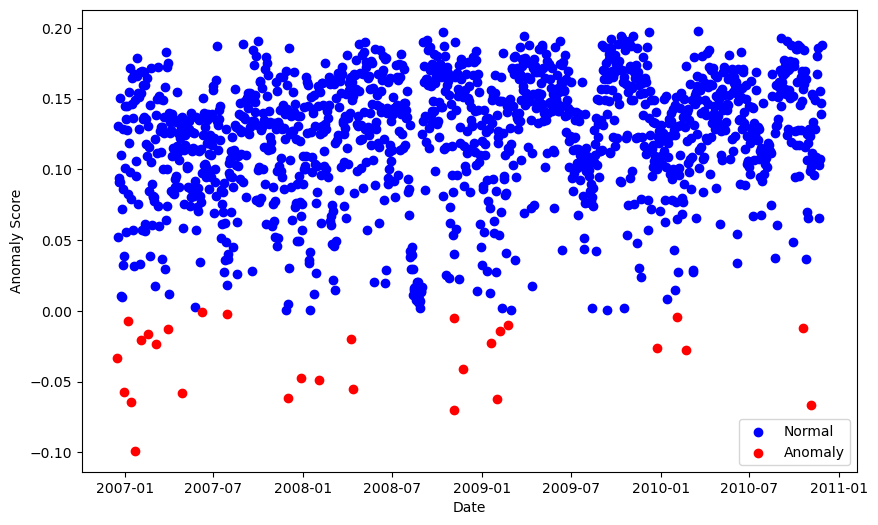

In [14]:
#Visualization of the results
plt.figure(figsize=(10, 6))

# Plot normal instances
normal = data_aggregated[data_aggregated['anomaly'] == 1]
plt.scatter(normal['Date'], normal['anomaly_score'], color='blue', label='Normal')

# Plot anomalies
anomalies = data_aggregated[data_aggregated['anomaly'] == -1]
plt.scatter(anomalies['Date'], anomalies['anomaly_score'], color='red', label='Anomaly')

plt.xlabel('Date')
plt.ylabel('Anomaly Score')
plt.legend()

## KernalSHAP with Anomaly Score

In [15]:
# Using the anomaly score and TreeSHAP (This code won't work)
explainer = shap.TreeExplainer(iso_forest.decision_function, features)
shap_values = explainer(features)

InvalidModelError: Model type not yet supported by TreeExplainer: <class 'method'>

In [16]:
# Select all anomalies and 100 random normal instances
normal_sample = np.random.choice(normal.index, 100, replace=False)
sample = np.append(anomalies.index, normal_sample)

len(sample) # 129

129

In [17]:
# Using the anomaly score and KernalSHAP
explainer = shap.Explainer(iso_forest.decision_function, features)
shap_values = explainer(features.iloc[sample])

PermutationExplainer explainer: 130it [00:27,  3.47it/s]                         


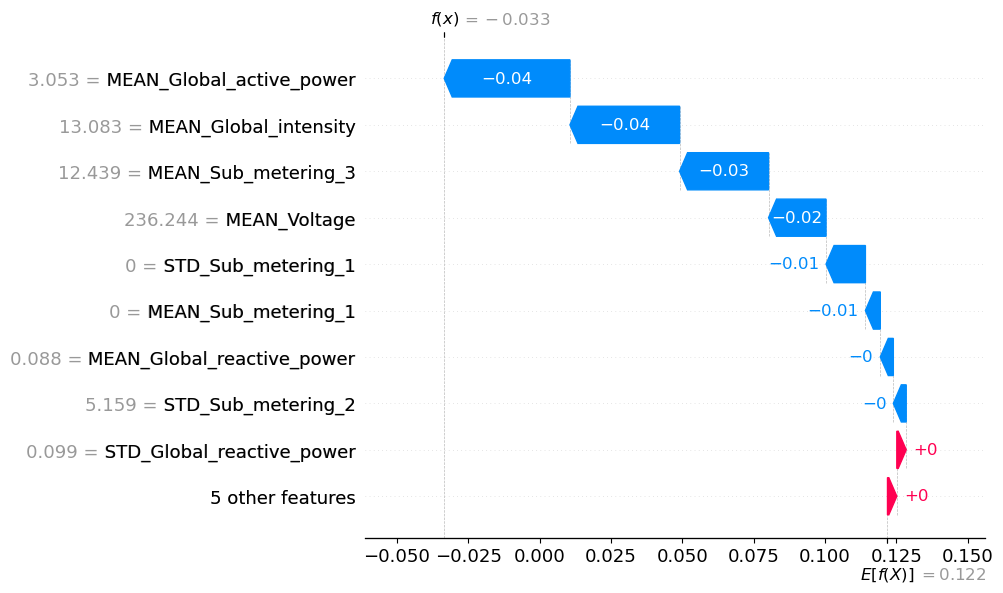

In [18]:
# Plot waterfall plot for an anomaly
shap.plots.waterfall(shap_values[0])

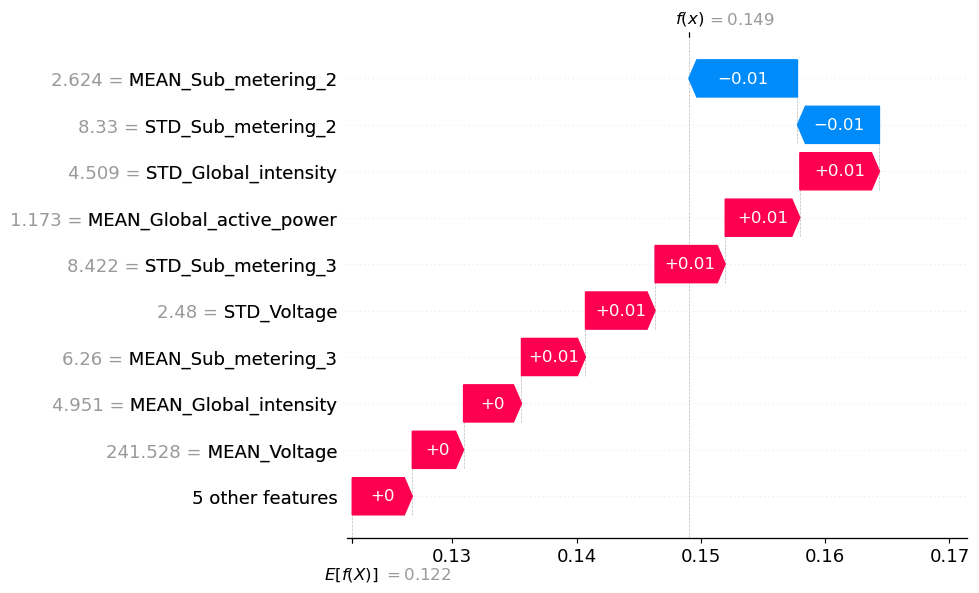

In [21]:
# Plot the waterfall plot of a normal instance
shap.plots.waterfall(shap_values[102])

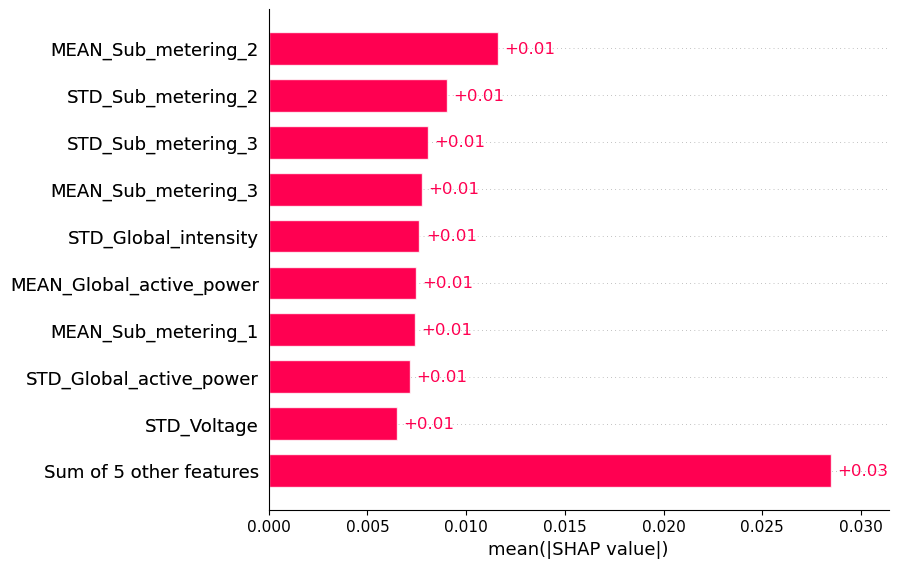

In [22]:
# MeanSHAP Plot
shap.plots.bar(shap_values)

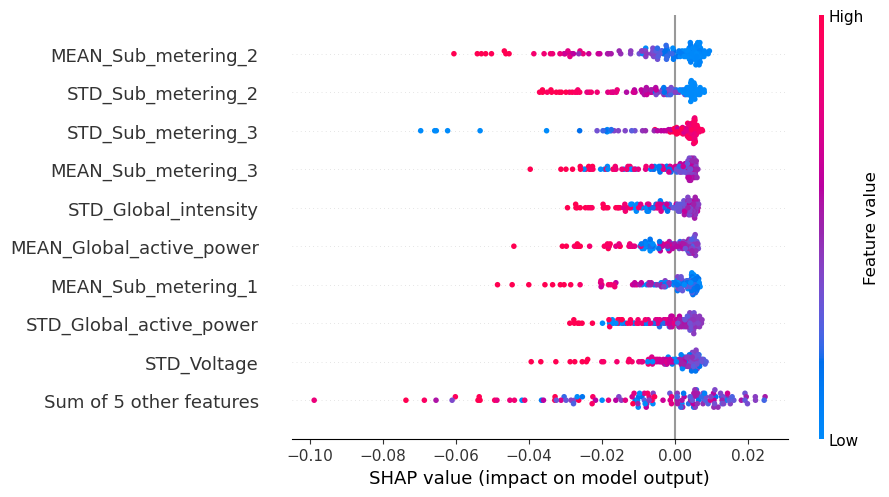

In [23]:
# Bee Swarm Plot
shap.plots.beeswarm(shap_values)

## TreeSHAP with Path Length

In [26]:
# Calculate SHAP Values
explainer = shap.TreeExplainer(iso_forest)
shap_values = explainer(features)

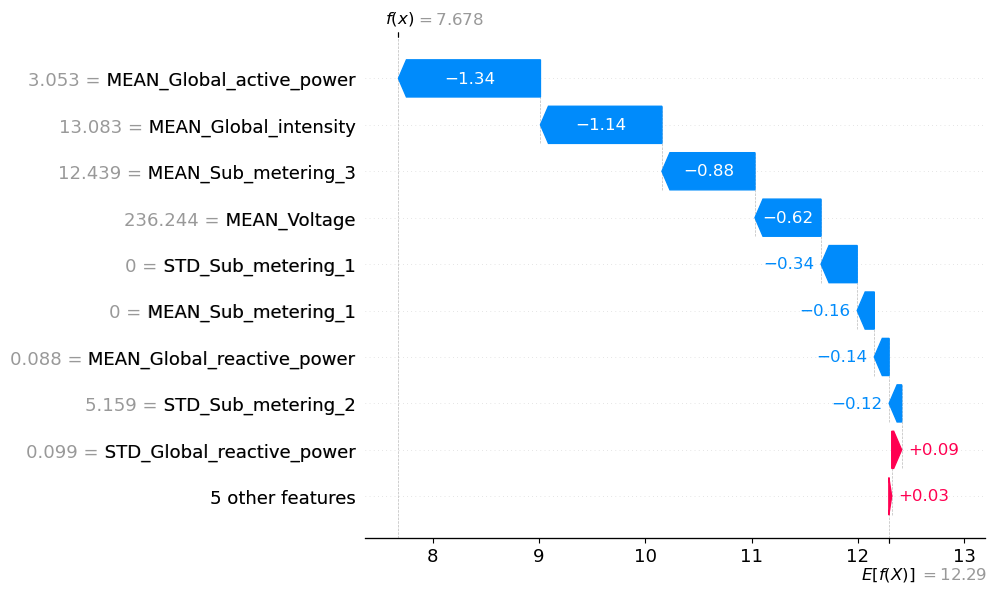

In [27]:
# Waterfall plot for anomaly
shap.plots.waterfall(shap_values[0])

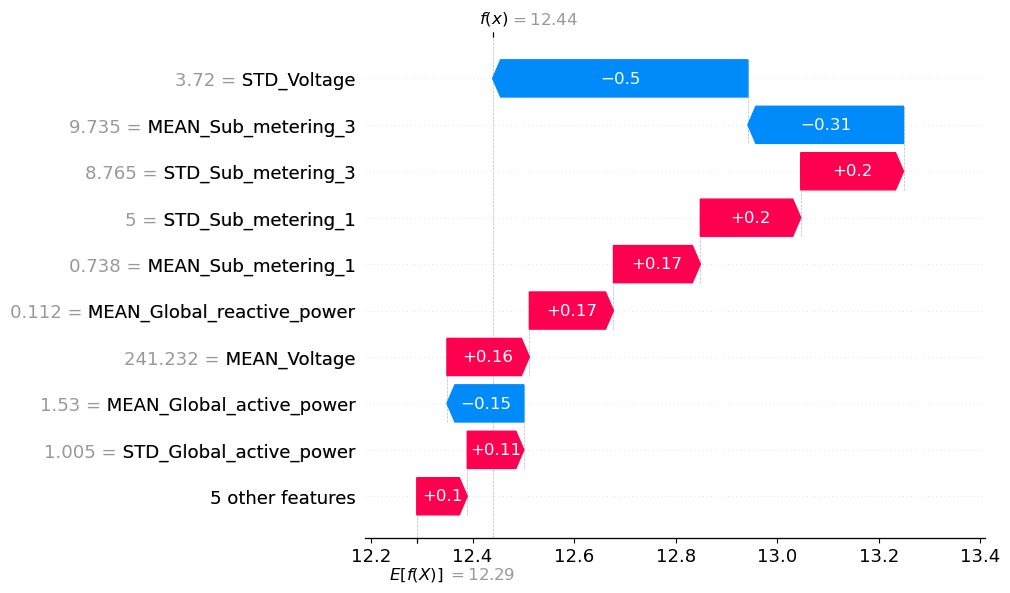

In [29]:
# Waterfall plot for normal instance
shap.plots.waterfall(shap_values[2])

Text(0, 0.5, 'Average Path Length f(x)')

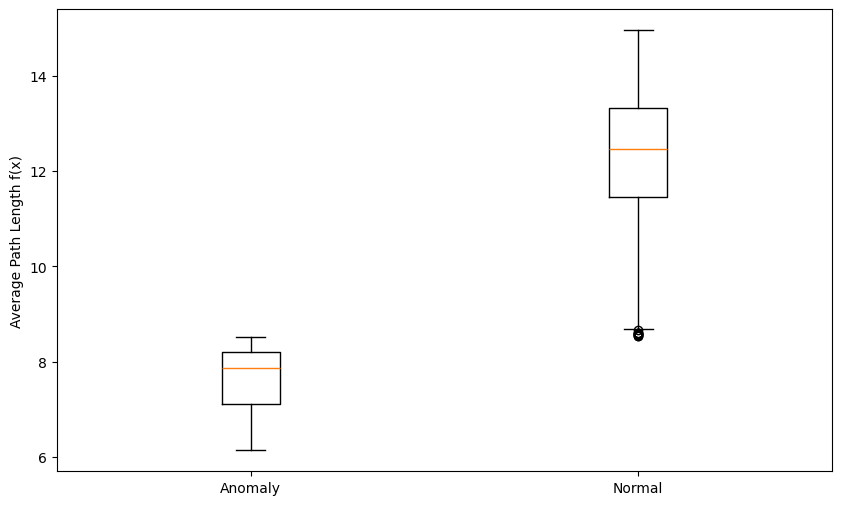

In [31]:
# Calculate f(x)
path_length = shap_values.base_values + shap_values.values.sum(axis=1)

# Get f(x) for anomalies and normal instances
anomalies = data_aggregated[data_aggregated['anomaly'] == -1]
path_length_anomalies = path_length[anomalies.index]

normal = data_aggregated[data_aggregated['anomaly'] == 1]
path_length_normal = path_length[normal.index]

# Plot boxplots for f(x)
plt.figure(figsize=(10, 6))
plt.boxplot([path_length_anomalies, path_length_normal], labels=['Anomaly', 'Normal']) 
plt.ylabel('Average Path Length f(x)')

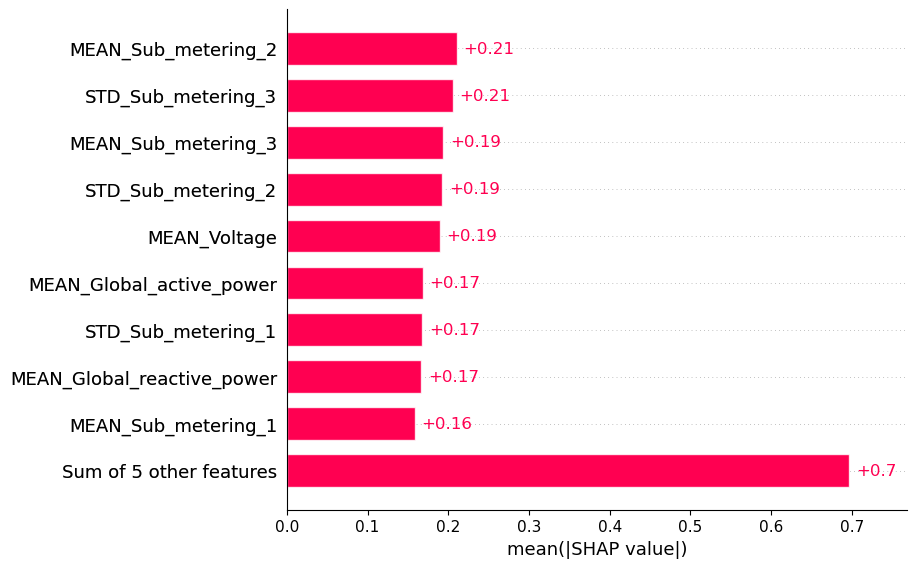

In [32]:
# MeanSHAP Plot
shap.plots.bar(shap_values)

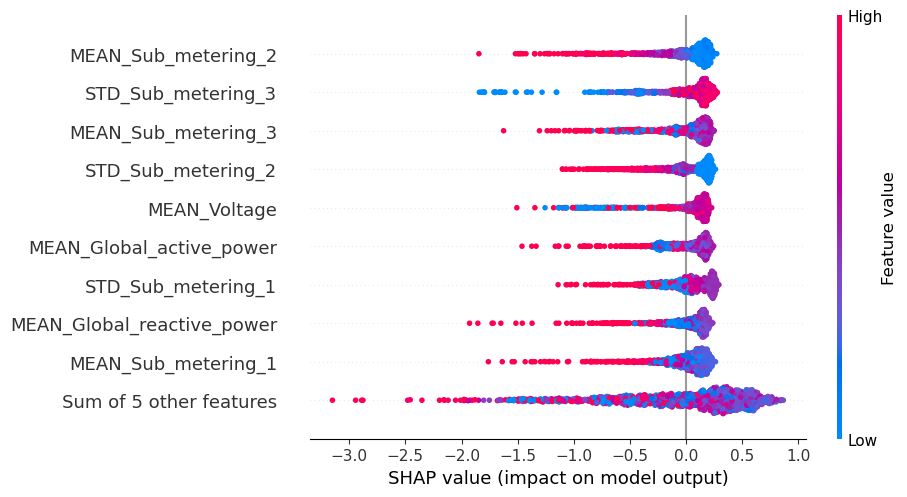

In [33]:
# MeanSHAP Beeswarm Plot
shap.plots.beeswarm(shap_values)

In [34]:
# Interaction Values
shap_interaction_values = explainer.shap_interaction_values(features)

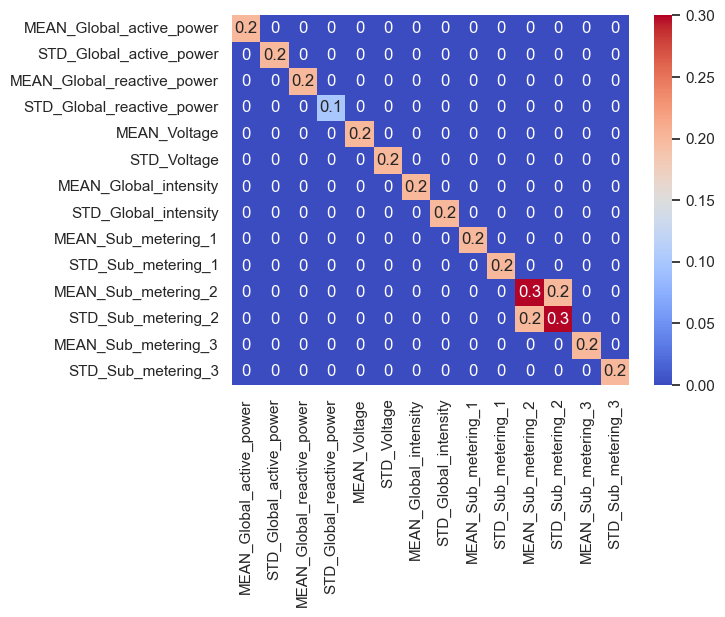

In [35]:
# Get absolute mean of matrices
mean_shap = np.abs(shap_interaction_values).mean(0)
mean_shap = np.round(mean_shap, 1)

df = pd.DataFrame(mean_shap, columns=features.columns, index=features.columns)

# Times off diagonal by 2
df.where(df.values == np.diag(df), df * 2, inplace=True)

# Display
sns.set(font_scale=1)
sns.heatmap(df, annot=True, cmap='coolwarm')
plt.yticks(rotation=0)

plt.savefig('shap_interaction_values.png', bbox_inches='tight', dpi=300)